# Taiwan Cross-Asset Macro Playbook

**Research question:** Which macro, external, and global variables best explain and predict Taiwan's FX (USD/TWD), equities (TAIEX proxy), and rates (policy rate)?

**Framing:** Taiwan is an export-led, semiconductor-heavy, current-account-surplus economy. We test whether external-sector and tech-cycle variables drive Taiwan assets, controlling for DXY, US yields, global tech beta, and volatility.

---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi'] = 120

## 1. Data Ingestion

Download market data (yfinance) and macro data (FRED). Results are cached to `data/raw/`.

In [2]:
from src.data_ingest import ingest_all

market_daily, macro_monthly = ingest_all(force_refresh=False)

── Market data (yfinance) ──
  ↻ loading cached usdtwd.csv
  ↻ loading cached ewt.csv
  ↻ loading cached tsmc.csv
  ↻ loading cached dxy.csv
  ↻ loading cached nasdaq.csv
  ↻ loading cached sox.csv
  ↻ loading cached vix.csv
  ↻ loading cached oil.csv
  ↻ loading cached us10y.csv
  ↻ loading cached us2y.csv

── US macro data (FRED) ──
  ↻ loading cached us_fed_funds.csv
  ↻ loading cached us10y_fred.csv
  ↻ loading cached us2y_fred.csv

── Taiwan macro (government open data) ──
  ↻ loading cached tw_cpi.csv
  ↻ loading cached tw_ip.csv
  ↻ loading cached tw_policy_rate.csv
  ↻ loading cached tw_exports.csv
  ↻ loading cached tw_exports.csv
  ↻ loading cached tw_imports.csv

  Market shape: (5464, 10)
  Macro  shape: (254, 8)


In [3]:
print('Market data columns:', market_daily.columns.tolist())
print('Date range:', market_daily.index.min(), '→', market_daily.index.max())
market_daily.tail()

Market data columns: ['usdtwd', 'ewt', 'tsmc', 'dxy', 'nasdaq', 'sox', 'vix', 'oil', 'us10y', 'us2y']
Date range: 2005-01-03 00:00:00 → 2025-12-30 00:00:00


,usdtwd,ewt,tsmc,dxy,nasdaq,sox,vix,oil,us10y,us2y
Date,,,,,,,,,,
2025-12-23,31.532200,62.500000,296.115631,97.940002,23561.839844,7184.540039,14.00,58.380001,4.169,3.43
2025-12-24,31.489500,62.529999,297.960388,97.980003,23613.310547,7204.370117,13.47,58.349998,4.136,3.43
2025-12-26,31.570200,63.020000,301.989044,98.019997,23593.099609,7207.640137,13.60,56.740002,4.136,3.43
2025-12-29,31.379999,63.330002,300.074463,98.040001,23474.349609,7178.270020,14.20,58.080002,4.116,3.43
2025-12-30,31.317801,63.709999,298.738190,98.239998,23419.080078,7169.100098,14.33,57.950001,4.130,3.43


In [4]:
print('Macro data columns:', macro_monthly.columns.tolist())
macro_monthly.tail()

Macro data columns: ['us_fed_funds', 'us10y_fred', 'us2y_fred', 'tw_cpi', 'tw_ip', 'tw_policy_rate', 'tw_exports', 'tw_imports']


,us_fed_funds,us10y_fred,us2y_fred,tw_cpi,tw_ip,tw_policy_rate,tw_exports,tw_imports
date,,,,,,,,
2025-10-01,4.09,4.06,3.52,110.43,116.56,1.7,1.855322e+09,1.194544e+09
2025-11-01,3.88,4.09,3.55,110.22,121.28,1.7,1.982888e+09,1.485012e+09
2025-12-01,3.72,4.14,3.50,110.29,133.38,1.7,1.958323e+09,1.349044e+09
2026-01-01,NaN,NaN,NaN,110.23,123.90,1.7,2.073372e+09,1.476924e+09
2026-02-01,NaN,NaN,NaN,111.02,109.46,1.7,NaN,NaN


## 2. Data Cleaning & Master Dataset

Resample market data to month-end, compute returns and YoY changes, merge into a single master DataFrame.

In [5]:
from src.data_cleaning import build_master

master = build_master(market_daily, macro_monthly)
master.tail()

── Cleaning & merging ──
  ✓ saved master_monthly.csv  shape=(254, 17)
  Date range: 2005-01-31 00:00:00 → 2026-02-28 00:00:00


,usdtwd_ret,ewt_ret,tsmc_ret,dxy_ret,nasdaq_ret,sox_ret,oil_ret,vix_level,us10y_level,us2y_level,tw_cpi_yoy,tw_ip_yoy,tw_exports_yoy,tw_imports_yoy,tw_trade_balance,tw_policy_rate_level,tw_rate_chg
Date,,,,,,,,,,,,,,,,,
2025-10-31,0.894666,4.762652,7.569190,2.076308,4.699694,13.482961,-2.228635,17.440001,4.101,3.605,1.367725,15.887850,40.490768,9.103643,660777836.0,1.7,0.0
2025-11-30,1.900379,-3.210797,-2.969072,-0.340685,-1.514319,-2.815325,-3.984914,16.350000,4.017,3.504,1.091443,18.391253,50.095272,39.480399,497876018.0,1.7,0.0
2025-12-31,0.009904,3.297152,3.045765,-1.226625,0.228500,2.049069,-1.024763,14.330000,4.130,3.430,1.202055,23.078343,38.424062,10.874633,609278833.0,1.7,0.0
2026-01-31,0.009904,3.297152,3.045765,-1.226625,0.228500,2.049069,-1.024763,14.330000,4.130,3.430,0.501459,27.876974,62.875596,56.755708,596448430.0,1.7,0.0
2026-02-28,0.009904,3.297152,3.045765,-1.226625,0.228500,2.049069,-1.024763,14.330000,4.130,3.430,1.741202,17.825619,62.875596,56.755708,596448430.0,1.7,0.0


## 3. Feature Engineering

Add lagged predictors (1-month lag) and regime flags (VIX, DXY).

In [6]:
from src.feature_engineering import engineer_features

df = engineer_features(master)
print(f'\nFinal dataset shape: {df.shape}')
df.tail()

── Feature engineering ──
  ✓ saved features_monthly.csv  shape=(254, 29)
  Core features available: 5/5
  Rich features available: 12/12
  Pred features available: 10/10

Final dataset shape: (254, 29)


,usdtwd_ret,ewt_ret,tsmc_ret,dxy_ret,nasdaq_ret,sox_ret,oil_ret,vix_level,us10y_level,us2y_level,...,sox_ret_lag1,vix_level_lag1,us10y_level_lag1,oil_ret_lag1,tw_exports_yoy_lag1,tw_cpi_yoy_lag1,tw_ip_yoy_lag1,tw_trade_balance_lag1,regime_vix,regime_dxy
Date,,,,,,,,,,,,,,,,,,,,,
2025-10-31,0.894666,4.762652,7.569190,2.076308,4.699694,13.482961,-2.228635,17.440001,4.101,3.605,...,12.363509,16.280001,4.148,-2.562105,27.008504,1.113463,18.155447,376238007.0,0,0
2025-11-30,1.900379,-3.210797,-2.969072,-0.340685,-1.514319,-2.815325,-3.984914,16.350000,4.017,3.504,...,13.482961,17.440001,4.101,-2.228635,40.490768,1.367725,15.887850,660777836.0,0,0
2025-12-31,0.009904,3.297152,3.045765,-1.226625,0.228500,2.049069,-1.024763,14.330000,4.130,3.430,...,-2.815325,16.350000,4.017,-3.984914,50.095272,1.091443,18.391253,497876018.0,0,0
2026-01-31,0.009904,3.297152,3.045765,-1.226625,0.228500,2.049069,-1.024763,14.330000,4.130,3.430,...,2.049069,14.330000,4.130,-1.024763,38.424062,1.202055,23.078343,609278833.0,0,0
2026-02-28,0.009904,3.297152,3.045765,-1.226625,0.228500,2.049069,-1.024763,14.330000,4.130,3.430,...,2.049069,14.330000,4.130,-1.024763,62.875596,0.501459,27.876974,596448430.0,0,0


## 4. Exploratory Analysis

### 4.1 Summary Statistics

In [7]:
from src.config import TARGETS, CORE_FEATURES, RICH_FEATURES, OUT_TABLES
from src.utils import pct_missing, save_table

# Summary stats for key columns
key_cols = [v for v in TARGETS.values() if v in df.columns] + \
           [c for c in RICH_FEATURES if c in df.columns]
summary = df[key_cols].describe().T
save_table(summary, OUT_TABLES / 'summary_stats.csv')
summary.round(3)

  ✓ saved summary_stats.csv


,count,mean,std,min,25%,50%,75%,max
usdtwd_ret,237.0,2.814000e+00,4.964200e+01,-8.781400e+01,-8.070000e-01,1.000000e-02,8.950000e-01,7.583650e+02
ewt_ret,253.0,9.370000e-01,6.221000e+00,-1.842600e+01,-2.493000e+00,8.870000e-01,4.763000e+00,2.664200e+01
tw_rate_chg,253.0,4.500000e-02,7.508000e+00,-7.523300e+01,0.000000e+00,0.000000e+00,0.000000e+00,2.700000e+01
dxy_ret,253.0,7.800000e-02,2.177000e+00,-6.022000e+00,-1.404000e+00,0.000000e+00,1.537000e+00,7.778000e+00
nasdaq_ret,253.0,1.097000e+00,5.097000e+00,-1.773200e+01,-1.640000e+00,1.420000e+00,4.367000e+00,1.544700e+01
vix_level,254.0,1.919400e+01,8.060000e+00,9.510000e+00,1.364800e+01,1.673000e+01,2.268800e+01,5.989000e+01
us10y_level,254.0,2.956000e+00,1.140000e+00,5.360000e-01,2.049000e+00,2.833000e+00,3.979000e+00,5.138000e+00
tw_exports_yoy,134.0,8.520000e+00,1.484100e+01,-2.032800e+01,-2.564000e+00,5.334000e+00,1.944600e+01,6.287600e+01
sox_ret,253.0,1.427000e+00,7.317000e+00,-2.196900e+01,-3.227000e+00,1.869000e+00,6.140000e+00,1.858000e+01
oil_ret,253.0,6.600000e-01,1.103300e+01,-5.424500e+01,-5.596000e+00,9.290000e-01,6.756000e+00,8.837600e+01


### 4.2 Missing Data Report

In [8]:
missing = pct_missing(df)
save_table(missing, OUT_TABLES / 'missing_data.csv')
missing[missing['pct_missing'] > 0].head(20)

  ✓ saved missing_data.csv


,n_missing,pct_missing
us2y_level,199,78.35
tw_exports_yoy_lag1,121,47.64
tw_imports_yoy,120,47.24
tw_exports_yoy,120,47.24
tw_trade_balance_lag1,109,42.91
tw_trade_balance,108,42.52
usdtwd_ret,17,6.69
tw_cpi_yoy_lag1,13,5.12
tw_ip_yoy_lag1,13,5.12
tw_cpi_yoy,12,4.72


### 4.3 Data Dictionary

In [9]:
data_dict = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.values,
    'non_null': df.notna().sum().values,
    'pct_available': (df.notna().mean() * 100).round(1).values,
})
save_table(data_dict, OUT_TABLES / 'data_dictionary.csv')
data_dict

  ✓ saved data_dictionary.csv


,column,dtype,non_null,pct_available
0,usdtwd_ret,float64,237,93.3
1,ewt_ret,float64,253,99.6
2,tsmc_ret,float64,253,99.6
3,dxy_ret,float64,253,99.6
4,nasdaq_ret,float64,253,99.6
5,sox_ret,float64,253,99.6
6,oil_ret,float64,253,99.6
7,vix_level,float64,254,100.0
8,us10y_level,float64,254,100.0
9,us2y_level,float64,55,21.7


### 4.4 Key Time Series

  ✓ saved tw_exports_yoy.png


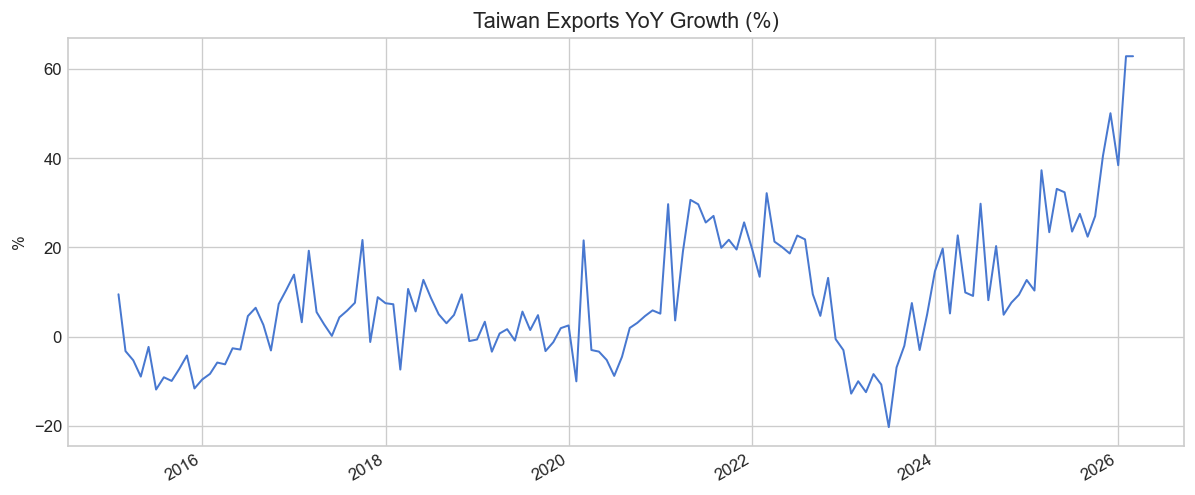

In [10]:
from src.plotting import plot_timeseries, plot_multi_ts, plot_correlation_heatmap, plot_rolling_corr

if 'tw_exports_yoy' in df.columns:
    plot_timeseries(df, 'tw_exports_yoy', 'Taiwan Exports YoY Growth (%)',
                    ylabel='%', name='tw_exports_yoy')
    plt.show()

  ✓ saved usdtwd_ret.png


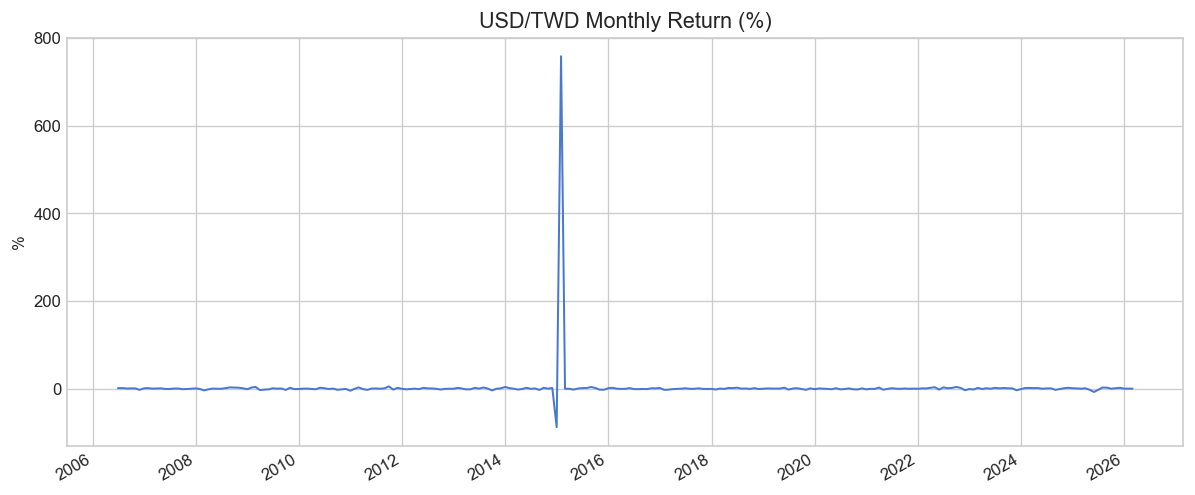

In [ ]:
if 'usdtwd_ret' in df.columns:
    plot_timeseries(df, 'usdtwd_ret', 'USD/TWD Monthly Return (%)',
                    ylabel='%', name='usdtwd_ret')
    plt.show()

    # Ignore below, data issues

  ✓ saved ewt_ret.png


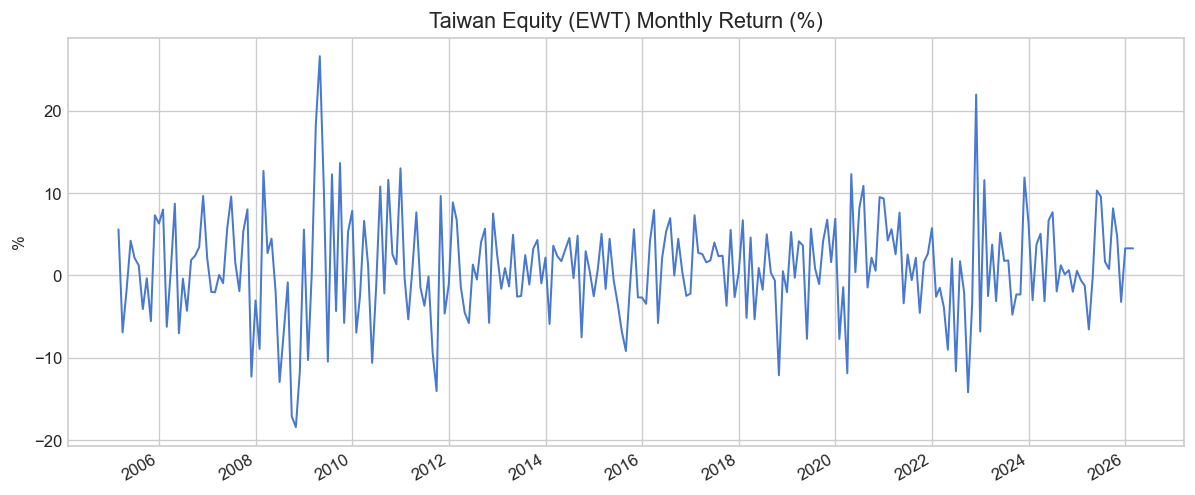

In [32]:
if 'ewt_ret' in df.columns:
    plot_timeseries(df, 'ewt_ret', 'Taiwan Equity (EWT) Monthly Return (%)',
                    ylabel='%', name='ewt_ret')
    plt.show()

  ✓ saved tw_rate_chg.png


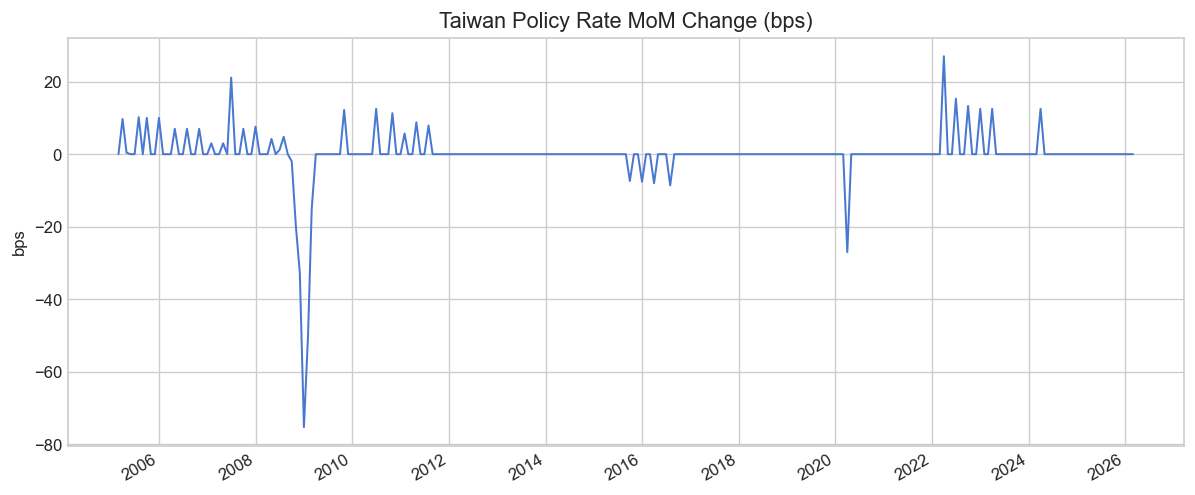

In [33]:
if 'tw_rate_chg' in df.columns:
    plot_timeseries(df, 'tw_rate_chg', 'Taiwan Policy Rate MoM Change (bps)',
                    ylabel='bps', name='tw_rate_chg')
    plt.show()

  ✓ saved tw_trade_balance.png


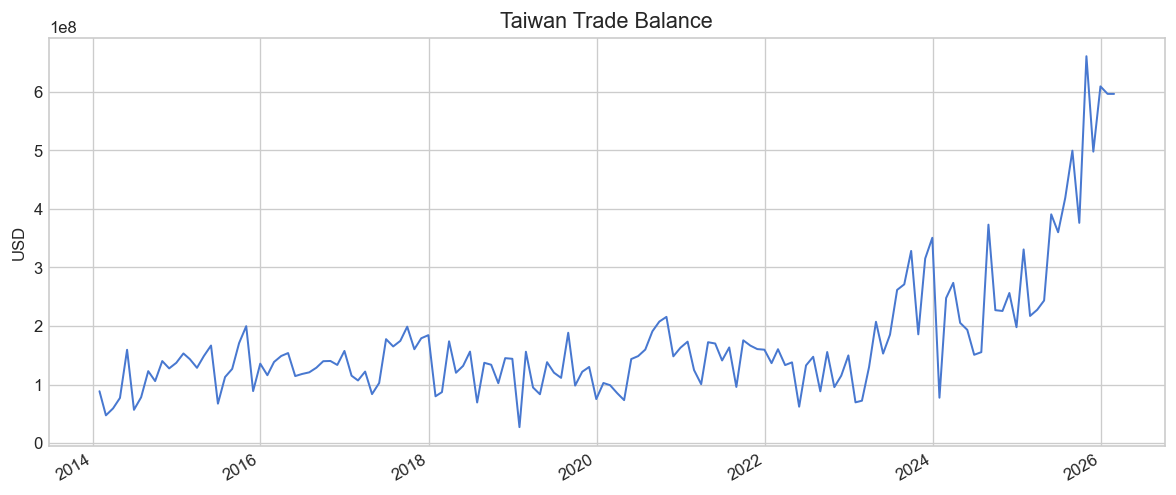

In [14]:
if 'tw_trade_balance' in df.columns:
    plot_timeseries(df, 'tw_trade_balance', 'Taiwan Trade Balance',
                    ylabel='USD', name='tw_trade_balance')
    plt.show()

### 4.5 Correlation Heatmap

  ✓ saved correlation_heatmap.png


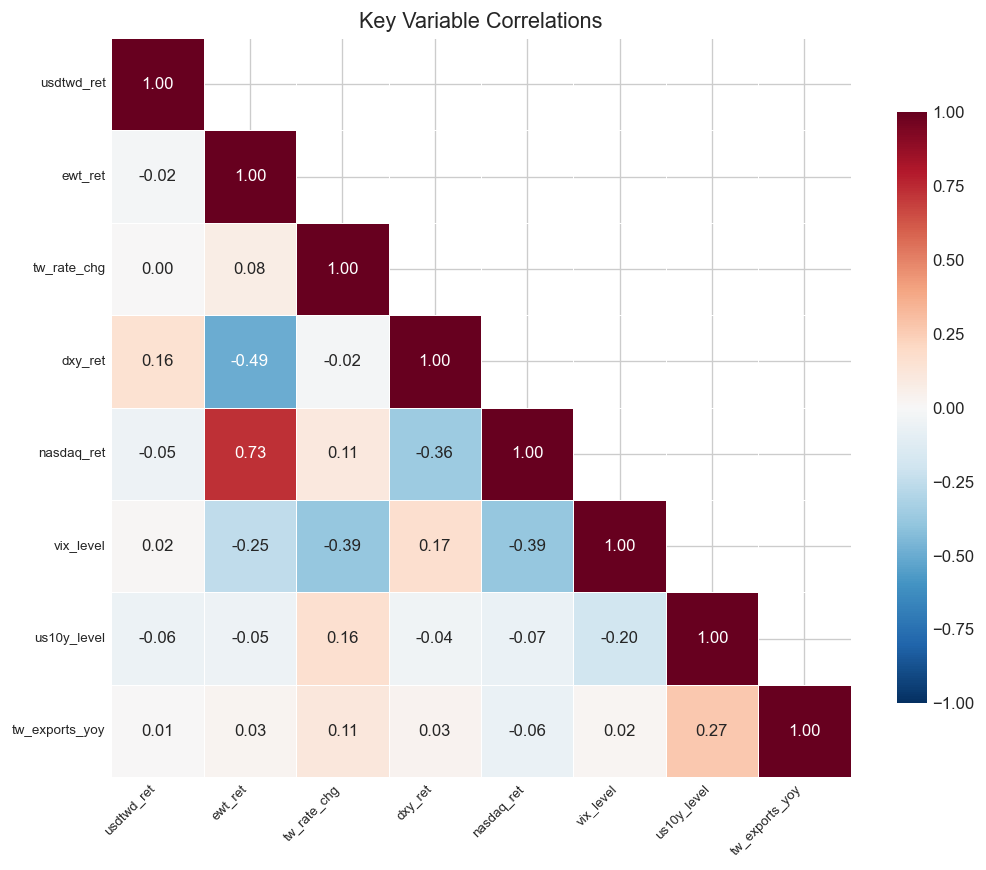

In [15]:
target_cols = [v for v in TARGETS.values() if v in df.columns]
heatmap_cols = target_cols + [c for c in CORE_FEATURES if c in df.columns]
if len(heatmap_cols) > 2:
    plot_correlation_heatmap(df, heatmap_cols,
                             'Key Variable Correlations',
                             name='correlation_heatmap')
    plt.show()

### 4.6 Rolling Correlations

  ✓ saved rolling_corr_fx.png


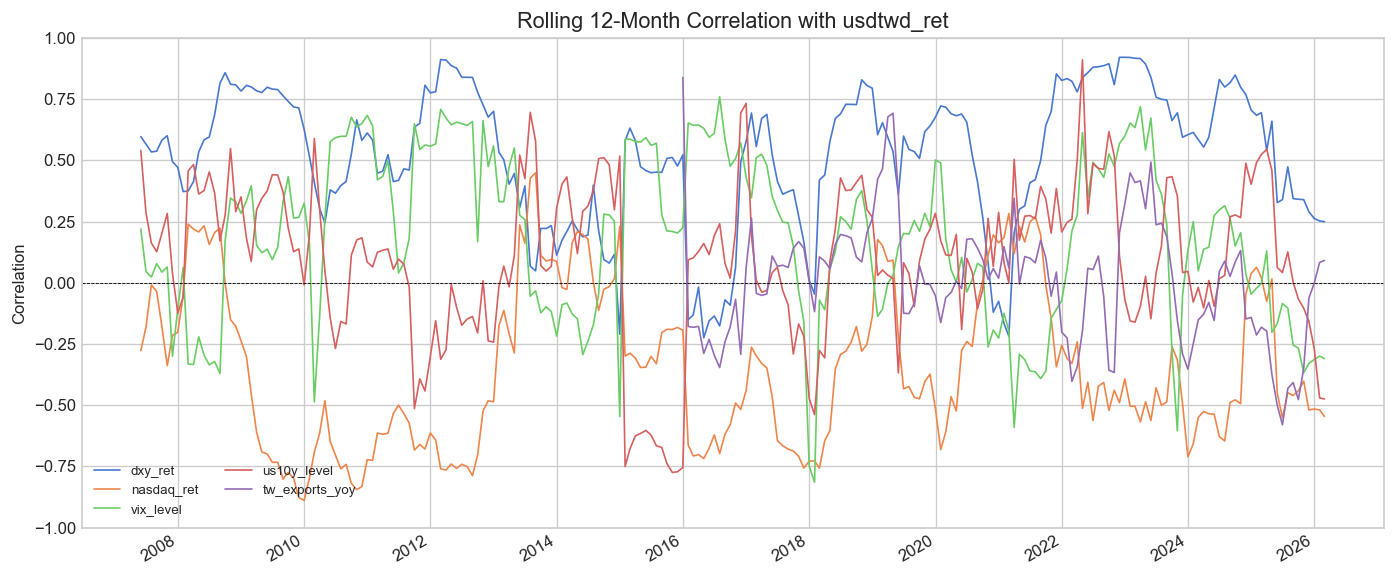

In [16]:
if 'usdtwd_ret' in df.columns:
    feats = [f for f in CORE_FEATURES if f in df.columns]
    if feats:
        plot_rolling_corr(df, 'usdtwd_ret', feats, name='rolling_corr_fx')
        plt.show()

  ✓ saved rolling_corr_eq.png


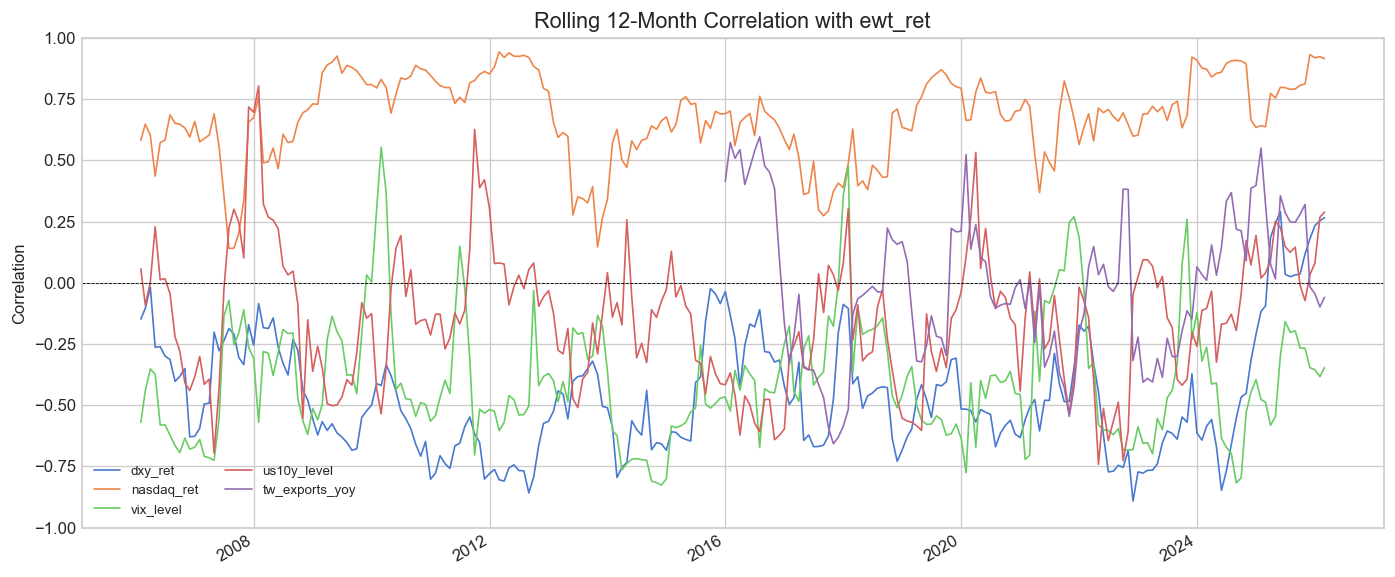

In [17]:
if 'ewt_ret' in df.columns:
    feats = [f for f in CORE_FEATURES if f in df.columns]
    if feats:
        plot_rolling_corr(df, 'ewt_ret', feats, name='rolling_corr_eq')
        plt.show()

---
## 5. Explanatory Models

For each target (FX, Equity, Rates) we run:
- **Core OLS**: DXY, Nasdaq, VIX, US 10Y, Taiwan exports YoY
- **Rich OLS**: Adds SOX, oil, US 2Y, Taiwan CPI/IP/trade balance/policy rate

In [18]:
from src.models_explanatory import run_all_explanatory

explanatory_results = run_all_explanatory(df)

── Explanatory models ──
  fx_ret_core                adj-R²=0.023  n=134
  fx_ret_rich                adj-R²=0.434  n=55
  eq_ret_core                adj-R²=0.558  n=134
  eq_ret_rich                adj-R²=0.754  n=55
  rate_chg_core              adj-R²=0.023  n=134
  rate_chg_rich              adj-R²=0.019  n=55
  ✓ saved explanatory_regressions.csv
  ✓ saved vif_rich_features.csv
  VIF table saved


In [19]:
# Display regression tables
reg_table = pd.read_csv(OUT_TABLES / 'explanatory_regressions.csv', index_col=0)
reg_table.round(4)

,coef,t_stat,p_value,label,r_squared,adj_r_squared,n_obs
const,21.8083,0.8006,0.4248,fx_ret_core,0.0594,0.0227,134
dxy_ret,7.7026,2.5697,0.0113,fx_ret_core,0.0594,0.0227,134
nasdaq_ret,-0.2125,-0.1718,0.8639,fx_ret_core,0.0594,0.0227,134
vix_level,-0.2557,-0.2652,0.7913,fx_ret_core,0.0594,0.0227,134
us10y_level,-4.6803,-0.8607,0.3910,fx_ret_core,0.0594,0.0227,134
tw_exports_yoy,0.0889,0.2246,0.8227,fx_ret_core,0.0594,0.0227,134
const,3.3177,1.0243,0.3116,fx_ret_rich,0.5595,0.4336,55
dxy_ret,0.4616,4.3585,0.0001,fx_ret_rich,0.5595,0.4336,55
nasdaq_ret,0.0143,0.1566,0.8763,fx_ret_rich,0.5595,0.4336,55
vix_level,-0.0697,-1.0101,0.3182,fx_ret_rich,0.5595,0.4336,55


In [20]:
# VIF for multicollinearity check
vif = pd.read_csv(OUT_TABLES / 'vif_rich_features.csv', index_col=0)
vif.round(2)

,feature,VIF
0,dxy_ret,1.27
1,nasdaq_ret,6.81
2,vix_level,3.33
3,us10y_level,53.84
4,tw_exports_yoy,5.22
5,sox_ret,5.72
6,oil_ret,1.33
7,us2y_level,45.72
8,tw_cpi_yoy,3.27
9,tw_ip_yoy,9.26


In [ ]:
# Statistical Significance Plot - Which factors actually matter?
from src.plotting import plot_significance

# Load regression results
reg_table = pd.read_csv(OUT_TABLES / 'explanatory_regressions.csv', index_col=0)

# Plot t-statistics for FX and Equities (rich models)
plot_significance(reg_table, targets=['fx_ret_rich', 'eq_ret_rich'], 
                  name='factor_significance')
plt.show()

---
## 6. Robustness: Taiwan-Only vs Global-Only Features

In [29]:
from src.models_explanatory import run_ols, ols_summary_table

taiwan_feats = [c for c in ['tw_exports_yoy', 'tw_cpi_yoy', 'tw_ip_yoy',
                             'tw_trade_balance', 'tw_policy_rate_level']
                if c in df.columns]
global_feats = [c for c in ['dxy_ret', 'nasdaq_ret', 'sox_ret', 'vix_level',
                             'us10y_level', 'oil_ret']
                if c in df.columns]

robustness_rows = []
for target_label, target_col in TARGETS.items():
    for feat_set, feat_name in [(taiwan_feats, 'TW-only'), (global_feats, 'Global-only')]:
        res = run_ols(df, target_col, feat_set, label=f'{target_label}_{feat_name}')
        if res is not None:
            robustness_rows.append({
                'target': target_label,
                'feature_set': feat_name,
                'adj_r2': round(res.rsquared_adj, 4),
                'n_obs': int(res.nobs),
            })

robustness_df = pd.DataFrame(robustness_rows)
if not robustness_df.empty:
    save_table(robustness_df, OUT_TABLES / 'robustness_tw_vs_global.csv')
    print('\nTaiwan-only vs Global-only R² comparison:')
    display(robustness_df)

  ✓ saved robustness_tw_vs_global.csv

Taiwan-only vs Global-only R² comparison:


,target,feature_set,adj_r2,n_obs
0,fx_ret,TW-only,0.0185,134
1,fx_ret,Global-only,0.0064,237
2,eq_ret,TW-only,0.0019,134
3,eq_ret,Global-only,0.6390,253
4,rate_chg,TW-only,0.1084,134
5,rate_chg,Global-only,0.1956,253


---
## 7. Conclusion: What Moves Taiwan's FX, Equities, and Rates?

This analysis examined which macro, external, and global variables drive Taiwan's key asset classes. The **significance plot above** makes it clear which factors matter—only bars crossing the dashed threshold lines (|t| > 1.96) are statistically significant.

### Taiwan Equities (EWT)

**Adjusted R² = 75%** — Taiwan equities are highly explainable.

**Significant Drivers:**
- **Semiconductor cycle (SOX)**: t = +5.5 *** → When global semiconductor stocks rise 1%, Taiwan equities rise ~0.6%
- **USD strength (DXY)**: t = -2.6 ** → A stronger dollar hurts Taiwan stocks (tighter global liquidity, reduced EM appetite)

**Not Significant:** Taiwan CPI, industrial production, exports, trade balance, policy rate — local macro adds little once global tech is accounted for.

> **Takeaway:** Taiwan's stock market is essentially a **global semiconductor play**.

---

### Taiwan Currency (USD/TWD)

**Adjusted R² = 43%** — Moderate explanatory power.

**Significant Drivers:**
- **USD strength (DXY)**: t = +4.4 *** → Global dollar strength directly lifts USD/TWD (TWD depreciates)
- **Semiconductor cycle (SOX)**: t = -2.1 * → Strong chip demand attracts foreign capital into Taiwan → TWD appreciates

**Not Significant:** Balance of payments factors (exports, imports, trade balance) are NOT significant. This likely reflects:
1. Active central bank FX intervention dampening fundamental effects
2. Taiwan's persistent current account surplus already priced in
3. Trade data released with lag, so markets price it in advance

> **Takeaway:** TWD moves with **global USD dynamics**, with a secondary boost from semiconductor demand.

---

### Taiwan Policy Rate

**Adjusted R² ≈ 2%** — Essentially unexplained by our variables.

No factors are statistically significant. Taiwan's central bank (CBC) decisions are **discretionary** and incorporate qualitative factors not captured by standard macro data.

---

### Summary

| Asset | Primary Driver | Secondary Driver | What Doesn't Matter |
|-------|---------------|------------------|--------------------|
| **Equities** | Semiconductor cycle (SOX) | USD strength (DXY) | Local macro (CPI, IP, exports) |
| **Currency** | USD strength (DXY) | Semiconductor cycle (SOX) | Balance of payments |
| **Rates** | — | — | Everything tested |

### Key Insight

Taiwan's financial markets are **globally integrated** through the **semiconductor supply chain**. For investors and analysts:

- **Track SOX and DXY** — these explain most of the variation in Taiwan assets
- **Local macro releases are secondary** — they provide limited additional signal once global factors are accounted for
- **Don't rely on trade balance for FX forecasting** — despite Taiwan's large surplus, it's not a significant driver in our model


In [30]:
print('\n=== Project complete ===')
print(f'Charts saved to: outputs/charts/')
print(f'Tables saved to: outputs/tables/')
print(f'Processed data:  data/processed/')


=== Project complete ===
Charts saved to: outputs/charts/
Tables saved to: outputs/tables/
Processed data:  data/processed/
